In [2]:
import pandas as pd

prices = pd.Series([100, 102, 99, 101, 104], index=pd.date_range("2024-01-01", periods=5))
signal = pd.Series([1, 1, 0, 1, 1], index=prices.index)

market_return = prices.pct_change().fillna(0)
position = signal.shift(1).fillna(0).astype(int)
strategy_return = market_return * position

pd.DataFrame({
    "price": prices,
    "signal": signal,
    "position": position,
    "market": market_return.round(4),
    "strategy": strategy_return.round(4),
})

,price,signal,position,market,strategy
2024-01-01,100,1,0,0.0000,0.0000
2024-01-02,102,1,1,0.0200,0.0200
2024-01-03,99,0,1,-0.0294,-0.0294
2024-01-04,101,1,0,0.0202,0.0000
2024-01-05,104,1,1,0.0297,0.0297


In [6]:
from backtester.data import load_prices
from backtester.strategy import sma_crossover

spy = load_prices('SPY', '2015-01-01', '2026-01-01')
signals = sma_crossover(spy['Adj Close'])

market_returns = spy['Adj Close'].pct_change().fillna(0)
positions = signals.shift(1).fillna(0).astype(int)
strategy_returns = market_returns * positions

results = pd.DataFrame({
    "price": spy['Adj Close'],
    "signal": signals,
    "position": positions,
    "market": market_returns.round(4),
    "strategy": strategy_returns.round(4),
})

results.loc['2020-02-28':'2020-03-06'].round(4)

Loaded SPY from cache: SPY_2015-01-01_2026-01-01.csv


,price,signal,position,market,strategy
Date,,,,,
2020-02-28,269.3779,1,1,-0.0042,-0.0042
2020-03-02,281.0436,1,1,0.0433,0.0433
2020-03-03,272.9968,0,1,-0.0286,-0.0286
2020-03-04,284.4715,0,0,0.0420,0.0000
2020-03-05,275.0152,0,0,-0.0332,-0.0000
2020-03-06,270.4689,0,0,-0.0165,-0.0000


In [8]:
cost_rate = 0.001

trades = positions.diff().abs().fillna(0)
cost = trades * cost_rate
net_return = strategy_returns - cost

pd.DataFrame({
    "position": positions,
    "trades": trades,
    "cost": cost.round(4),
    "strategy": strategy_returns.round(4),
    "net": net_return.round(4),
})

,position,trades,cost,strategy,net
Date,,,,,
2015-01-02,0,0.0,0.0,0.0000,0.0000
2015-01-05,0,0.0,0.0,-0.0000,-0.0000
2015-01-06,0,0.0,0.0,-0.0000,-0.0000
2015-01-07,0,0.0,0.0,0.0000,0.0000
2015-01-08,0,0.0,0.0,0.0000,0.0000
...,...,...,...,...,...
2025-12-24,1,0.0,0.0,0.0035,0.0035
2025-12-26,1,0.0,0.0,-0.0001,-0.0001
2025-12-29,1,0.0,0.0,-0.0036,-0.0036


In [18]:
results["trades"] = results["position"].diff().abs().fillna(0)
results["cost"] = results["trades"] * cost_rate
results["net"] = results["strategy"] - results["cost"]

In [10]:
results["trades"].sum()

np.float64(51.0)

In [11]:
results["cost"].sum()

np.float64(0.051000000000000004)

In [19]:
results.loc["2016-05-25":"2016-06-01"].round(4)

,price,signal,position,market,strategy,trades,cost,net
Date,,,,,,,,
2016-05-25,176.9059,1,1,0.0068,0.0068,0.0,0.000,0.0068
2016-05-26,176.9566,0,1,0.0003,0.0003,0.0,0.000,0.0003
2016-05-27,177.7175,1,0,0.0043,0.0000,1.0,0.001,-0.0010
2016-05-31,177.3793,1,1,-0.0019,-0.0019,1.0,0.001,-0.0029
2016-06-01,177.7427,1,1,0.0020,0.0020,0.0,0.000,0.0020


In [17]:
initial_capital = 10_000

equity = initial_capital * (1 + net_return).cumprod()
benchmark = initial_capital * (1 + market_returns).cumprod()

pd.DataFrame({
    "net": net_return.round(4),
    "growth": (1 + net_return).round(4),
    "equity": equity.round(2),
    "market": market_returns.round(4),
    "benchmark": benchmark.round(2),
})


,net,growth,equity,market,benchmark
Date,,,,,
2015-01-02,0.0000,1.0000,10000.00,0.0000,10000.00
2015-01-05,-0.0000,1.0000,10000.00,-0.0181,9819.41
2015-01-06,-0.0000,1.0000,10000.00,-0.0094,9726.91
2015-01-07,0.0000,1.0000,10000.00,0.0125,9848.12
2015-01-08,0.0000,1.0000,10000.00,0.0177,10022.88
...,...,...,...,...,...
2025-12-24,0.0035,1.0035,22938.55,0.0035,40470.23
2025-12-26,-0.0001,0.9999,22936.22,-0.0001,40466.13
2025-12-29,-0.0036,0.9964,22854.48,-0.0036,40321.92


In [21]:
results["equity"] = initial_capital * (1 + results["net"]).cumprod()
results["benchmark"] = initial_capital * (1 + results["market"]).cumprod()
results[["equity", "benchmark"]].iloc[-1]

equity       22675.172350
benchmark    40007.181468
Name: 2025-12-31 00:00:00, dtype: float64

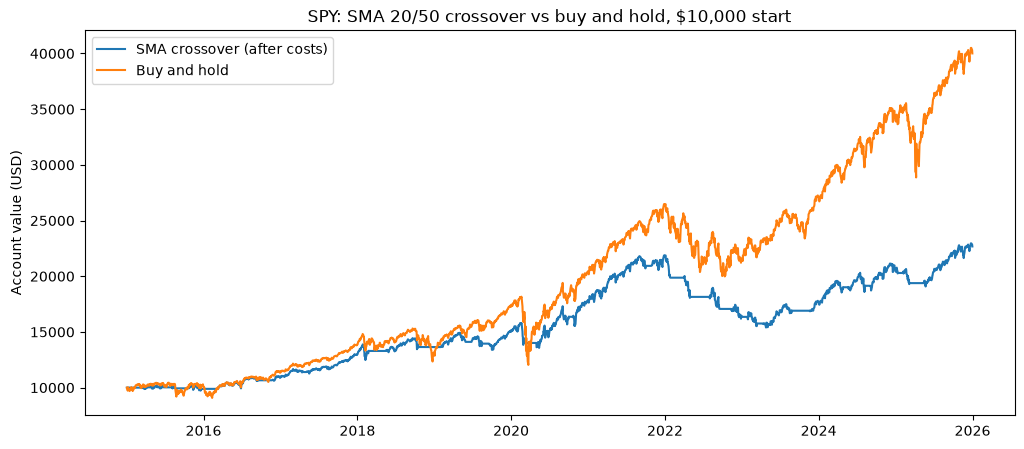

In [22]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(results.index, results["equity"], label="SMA crossover (after costs)")
ax.plot(results.index, results["benchmark"], label="Buy and hold")
ax.set_title("SPY: SMA 20/50 crossover vs buy and hold, $10,000 start")
ax.set_ylabel("Account value (USD)")
ax.legend()
plt.show()

In [23]:
prices = pd.Series([100, 101, 103, 102, 100, 99, 104], index=pd.date_range("2024-01-01", periods=7))
signal = pd.Series([0, 1, 1, 0, 0, 1, 1], index=prices.index)
cost_rate = 0.001

change = signal.diff()
entries = list(signal.index[change == 1])
exits = list(signal.index[change == -1])

if len(entries) > len(exits):
    exits.append(signal.index[-1])

trade_log = pd.DataFrame({"entry_date": entries, "exit_date": exits})
trade_log["entry_price"] = prices.loc[entries].to_numpy()
trade_log["exit_price"] = prices.loc[exits].to_numpy()
trade_log["days_held"] = (trade_log["exit_date"] - trade_log["entry_date"]).dt.days
trade_log["net_return"] = trade_log["exit_price"] / trade_log["entry_price"] - 1 - 2 * cost_rate

trade_log.round({"net_return": 4})

,entry_date,exit_date,entry_price,exit_price,days_held,net_return
0,2024-01-02,2024-01-04,101,102,2,0.0079
1,2024-01-06,2024-01-07,99,104,1,0.0485


In [25]:
changes = signals.diff()
entries = list(signals.index[changes == 1])
exits = list(signals.index[changes == -1])

if len(entries) > len(exits):
    exits.append(signals.index[-1])

trade_log = pd.DataFrame({"entry_date": entries, "exit_date": exits})
trade_log["entry_price"] = spy["Adj Close"].loc[entries].to_numpy()
trade_log["exit_price"] = spy["Adj Close"].loc[exits].to_numpy()
trade_log["days_held"] = (trade_log["exit_date"] - trade_log["entry_date"]).dt.days
trade_log["net_return"] = trade_log["exit_price"] / trade_log["entry_price"] - 1 - 2 * cost_rate

trade_log.round({"entry_price": 2, "exit_price": 2, "net_return": 4})

,entry_date,exit_date,entry_price,exit_price,days_held,net_return
0,2015-03-16,2015-04-20,171.86,173.68,35,0.0086
1,2015-04-24,2015-06-25,175.17,174.53,62,-0.0056
2,2015-08-03,2015-08-19,174.48,173.25,16,-0.0090
3,2015-10-22,2015-12-22,171.60,171.14,61,-0.0047
4,2016-03-09,2016-05-26,167.67,176.96,78,0.0534
5,2016-05-27,2016-09-19,177.72,182.25,115,0.0235
6,2016-11-21,2017-04-19,188.01,201.40,149,0.0693
7,2017-05-03,2017-09-07,205.75,214.03,127,0.0382
8,2017-09-08,2018-02-23,213.78,240.57,168,0.1233
9,2018-05-15,2018-10-18,238.36,245.22,156,0.0268


In [26]:
initial_capital * (1 + trade_log["net_return"]).prod()

np.float64(22670.171666469174)

In [27]:
trade_log.sort_values("net_return").head(3)

,entry_date,exit_date,entry_price,exit_price,days_held,net_return
16,2022-04-01,2022-05-02,426.426086,390.234680,31,-0.086871
17,2022-08-01,2022-09-16,388.412262,366.072083,46,-0.059517
15,2021-10-28,2022-01-25,428.667786,407.788483,89,-0.050707
